# Aula 34: Recursão



*"Para entender recursão, precisa-se primeiro entender recursão."*

## 1. Função recursiva

Uma função recursiva é uma função que chama a si mesma durante a execução.

Toda função recursiva precisa de dois componentes obrigatórios para funcionar de forma correta: o **caso base** e o **passo recursivo**.

- Na condição do caso base, a função retorna um valor diretamente.
- Na condição do caso recursivo, a função faz uma nova chamada a si mesma para outra entrada (geralmente menor).


In [53]:
def fatorial(n):
    if n <= 1:   # CONDIÇÃO DO CASO BASE
        return 1 # CASO BASE
    return n * fatorial(n - 1) # PASSO RECURSIVO

for n in range(10):
    print(f"{n}! = {fatorial(n)}")

0! = 1
1! = 1
2! = 2
3! = 6
4! = 24
5! = 120
6! = 720
7! = 5040
8! = 40320
9! = 362880


Se o caso base estiver ausente ou o passo recursivo não avançar em direção a ele, a execução entra em repetição infinita.

In [54]:
def f_sem_caso_base():
    return 0 + f_sem_caso_base()

#f_sem_caso_base()

In [55]:
def f_sem_avancar(n):
    if n == 0:
        return 100
    return f_sem_avancar(n + 1)

#f_sem_avancar(1)

## 2. Pilha de execução

Cada vez que uma função é executada, o interpretador reserva um espaço de memória chamado quadro de ativação. Esse quadro guarda os parâmetros, as variáveis locais e o endereço de retorno (onde a execução prossegue após a função retornar). Esses quadros são armazenados em uma estrutura chamada **pilha de execução**.


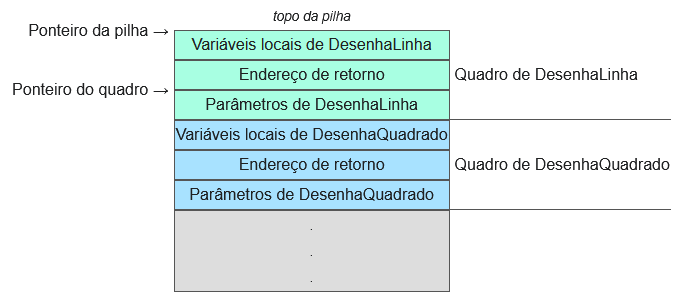

(Imagem do [Wikipedia](https://pt.wikipedia.org/wiki/Pilha_de_chamada))

Na recursão, o quadro da chamada atual permanece na memória enquanto aguarda o resultado da chamada seguinte. Os novos quadros vão sendo empilhados até o caso base ser alcançado. Quando a condição do caso base é satisfeita, as funções começam a retornar valores e os quadros são retirados da memória na ordem inversa à que entraram.

In [56]:
def rastrear(n):
    print(f"Início de rastrear({n})")
    if n == 0:
        print("CASO BASE ALCANÇADO")
        return
    rastrear(n - 1)
    print(f"Fim de rastrear({n})")

rastrear(3)

Início de rastrear(3)
Início de rastrear(2)
Início de rastrear(1)
Início de rastrear(0)
CASO BASE ALCANÇADO
Fim de rastrear(1)
Fim de rastrear(2)
Fim de rastrear(3)


Como os quadros ocupam memória até chegarmos no caso base, há um limite no número de chamadas recursivas no Python.

In [57]:
import sys
print(f"Limite de recursão: {sys.getrecursionlimit()}")

Limite de recursão: 1000


In [58]:
#rastrear(975) # não deu erro

In [59]:
#rastrear(976) # RecursionError

## 3. Recursão está por toda parte!

Várias operações aritméticas básicas possuem definições recursivas.

A multiplicação entre dois inteiros positivos, por exemplo, pode ser formulada como uma soma repetida. O produto entre os números `a` e `b` equivale a somar `a` com o resultado da multiplicação entre `a` e `b - 1`. Quando o multiplicando `b` atinge zero, o resultado é zero, o que define a parada.

As versões recursivas das operações abaixo não são nada eficientes: primeiro, porque algumas dessas operações conseguem ser feitas nativamente pelo computador (multiplicação); e outras porque um laço `for` seria mais rápido do que ficar criando quadros de ativação repetidamente (assunto da seção 5). Ainda assim, vale a pena o exercício.

In [60]:
def multiplicar(a, b):
    if b == 0:
        return 0
    return a + multiplicar(a, b - 1)

print(f"5 * 4 = {multiplicar(5, 4)}")
print(f"7 * 3 = {multiplicar(7, 3)}")

5 * 4 = 20
7 * 3 = 21


In [61]:
def potencia(base, expoente):
    if expoente == 0:
        return 1
    return base * potencia(base, expoente - 1)

print(f"2 ** 5 = {potencia(2, 5)}")
print(f"3 ** 4 = {potencia(3, 4)}")

2 ** 5 = 32
3 ** 4 = 81


In [62]:
def somatorio(n):
    if n <= 0:
        return 0
    return n + somatorio(n - 1)

print(f"Somatório de 1 até 10 é {somatorio(10)}")

Somatório de 1 até 10 é 55


Para listas e strings, em muitos casos o caso base natural para a recursão é lidar com lista (ou string) vazia. E o passo recursivo lida com uma lista (ou string) de menor tamanho.

In [63]:
def somar_lista(valores):
    if valores == []:
        return 0
    print(valores)
    return valores[0] + somar_lista(valores[1:])

numeros = [4, 7, 2, 9, 1]
print(f"Lista: {numeros}")
print(f"Soma: {somar_lista(numeros)}")

Lista: [4, 7, 2, 9, 1]
[4, 7, 2, 9, 1]
[7, 2, 9, 1]
[2, 9, 1]
[9, 1]
[1]
Soma: 23


In [64]:
def inverter_texto(texto):
    if len(texto) <= 1:
        return texto
    return inverter_texto(texto[1:]) + texto[0]

palavra = "recursao"
print(f"Original: {palavra}")
print(f"Invertido: {inverter_texto(palavra)}")

Original: recursao
Invertido: oasrucer


In [65]:
def eh_palindromo(texto):
    if len(texto) <= 1:
        return True # TODA PALAVRA DE 0 OU 1 CARACTERES É PALÍNDROMO
    if texto[0] != texto[-1]:
        return False # TODA PALAVRA EM QUE O PRIMEIRO E ÚLTIMO CARACTERE SÃO DIFERENTES NÃO É PALÍNDROMO
     # AQUI, O PRIMEIRO E ÚLTIMO CARACTERE SÃO IGUAIS; ANALISAMOS O RESTANTE RECURSIVAMENTE
    return eh_palindromo(texto[1:-1])

exemplos = ["radar", "arara", "python", "osso"]
for termo in exemplos:
    print(f"'{termo}' é palíndromo? {eh_palindromo(termo)}")

'radar' é palíndromo? True
'arara' é palíndromo? True
'python' é palíndromo? False
'osso' é palíndromo? True


## 4. Múltiplas chamadas recursivas

Uma função recursiva pode realizar duas ou mais chamadas a si mesma dentro da mesma instrução. Quando isso ocorre, o fluxo de execução se ramifica em formato de árvore em vez de seguir uma linha reta.

A sequência de Fibonacci exemplifica essa ramificação. Por definição, os dois primeiros números da sequência valem 0 e 1. Qualquer termo posterior corresponde à soma dos dois termos que o antecedem na sequência.

In [66]:
def fibonacci(n):
    if n <= 1:
        return n
    return fibonacci(n - 1) + fibonacci(n - 2)

termos = [fibonacci(i) for i in range(10)]
print(f"Primeiros 10 termos: {termos}")

Primeiros 10 termos: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34]


Ao chamar `fibonacci(4)`, primeiro avaliamos o lado esquerdo da expressão chamando `fibonacci(3)`. Essa subchamada ramifica em `fibonacci(2)` e `fibonacci(1)`. Só depois de concluir todo o ramo esquerdo a execução parte para o ramo direito `fibonacci(2)`.

Esse comportamento gera retrabalho. O valor de `fibonacci(2)` precisa ser calculado por inteiro duas vezes distintas na mesma execução.

Vamos contar quantas chamadas estão sendo feitas:

In [67]:
chamadas = 0

def fibonacci_contado(n):
    global chamadas
    chamadas += 1
    if n <= 1:
        return n
    return fibonacci_contado(n - 1) + fibonacci_contado(n - 2)

for valor in [5, 10, 15, 20]:
    chamadas = 0
    resultado = fibonacci_contado(valor)
    print(f"F({valor}) = {resultado} com {chamadas} chamadas executadas")

F(5) = 5 com 15 chamadas executadas
F(10) = 55 com 177 chamadas executadas
F(15) = 610 com 1973 chamadas executadas
F(20) = 6765 com 21891 chamadas executadas


## 5. Recursão versus iteração

Todo problema resolvido por recursão também admite solução baseada iteração (laços `for` / `while`): se necessária, a pilha de execução pode ser implementada manualmente. Dependendo do problema, usar recursão pode ou não ser o mais natural.

- Funções iterativas atualizam variáveis no mesmo espaço de memória.
- Funções recursivas criam um novo quadro de memória a cada chamada.

A versão iterativa da função Fibonacci resolve o problema bem mais eficientemente:

In [68]:
def fibonacci_iterativo(n):
    if n <= 1:
        return n
    anterior = 0
    atual = 1
    for _ in range(2, n + 1):
        novo = anterior + atual
        anterior = atual
        atual = novo
    return atual

print(f"F(100) iterativo: {fibonacci_iterativo(100)}")

F(100) iterativo: 354224848179261915075


A versão recursiva demoraria ~36mil anos em um computador capaz de fazer 1 bilhão de chamadas recursivas por segundo. No Python, deve demorar mais de 1 milhão de anos.

In [69]:
#fibonacci(100) # verifiquem o resultado após 1 milhão de anos

Dá para resolver esse problema se anotarmos os resultados das chamadas que já foram feitas.

## 6. Otimização com memoização

O principal problema da recursão múltipla de Fibonacci é o recálculo contínuo de subproblemas já resolvidos.

A técnica de **memoização** elimina esse desperdício ao memorizar o resultado de cada chamada concluída em uma estrutura de consulta rápida, como um dicionário.

Antes de recursar, a função verifica se já foi computada resposta para a entrada atual.

In [70]:
memoria = {}

def fibonacci_memo(n):
    if n in memoria:
        return memoria[n]
    if n <= 1:
        return n

    memoria[n] = fibonacci_memo(n - 1) + fibonacci_memo(n - 2)
    return memoria[n]

print(f"F(100) com memoização: {fibonacci_memo(100)}") # NÃO DEMORA 1 MILHÃO DE ANOS!

F(100) com memoização: 354224848179261915075


Não é legal usar variáveis globais... Podemos aprimorar o código anterior da seguinte forma:

In [71]:
def fibonnaci_memo_local(n, memoria = None):
    if memoria is None:
        memoria = {}
    if n in memoria:
        return memoria[n]
    if n <= 1:
        return n

    memoria[n] = fibonnaci_memo_local(n - 1, memoria) + fibonnaci_memo_local(n - 2, memoria)
    return memoria[n]

print(f"F(100) com memoização local: {fibonnaci_memo_local(100)}") # NÃO DEMORA 1 MILHÃO DE ANOS E NÃO USA VARIÁVEL GLOBAL!
print(fibonnaci_memo_local(6))

F(100) com memoização local: 354224848179261915075
8


Podemos contar quantas chamadas estão sendo feitas.

In [72]:
contador = 0

def fibonnaci_memo_contado(n, memoria = None):
    global contador
    contador += 1

    if memoria is None:
        memoria = {}
    if n in memoria:
        return memoria[n]
    if n <= 1:
        return n

    memoria[n] = fibonnaci_memo_contado(n - 1, memoria) + fibonnaci_memo_contado(n - 2, memoria)
    return memoria[n]

print(f"F(100) com memoização local: {fibonnaci_memo_contado(100)}") # NÃO DEMORA 1 MILHÃO DE ANOS!
print(f"Número de chamadas recursivas: {contador}")

F(100) com memoização local: 354224848179261915075
Número de chamadas recursivas: 199


A biblioteca padrão do Python oferece uma forma de aplicar essa otimização sem a necessidade de gerenciar dicionários manualmente. O decorador `lru_cache`, disponível no módulo `functools`, intercepta as chamadas da função e armazena os retornos de forma transparente.

In [73]:
import functools

@functools.cache
def fibonacci_auto_memo(n):
    if n <= 1:
        return n
    return fibonacci_auto_memo(n - 1) + fibonacci_auto_memo(n - 2)

print(f"F(100) com @functools.cache: {fibonacci_auto_memo(100)}")
print(fibonacci_auto_memo.cache_info()) # as mesmas 199 chamadas! 98 atingiram o cache


F(100) com @functools.cache: 354224848179261915075
CacheInfo(hits=98, misses=101, maxsize=None, currsize=101)


## 7. Divisão e conquista

Uma estratégia muito usada para resolver problemas é a chamada **divisão e conquista**, que funciona assim:
1. Divida o problema em subproblemas menores.
2. Resolva (conquiste) os subproblemas menores, por recursão.
3. Combine as soluções dos subproblemas menores para achar a solução do problema original.

In [74]:
def maximo_divisao(lista):
    if len(lista) == 1:
        return lista[0]

    meio = len(lista) // 2
    maior_esquerda = maximo_divisao(lista[:meio])
    maior_direita = maximo_divisao(lista[meio:])

    return maior_esquerda if maior_esquerda > maior_direita else maior_direita

dados = [12, 45, 7, 89, 23, 56, 91, 34]
print(f"Lista de entrada: {dados}")
print(f"Maior valor encontrado: {maximo_divisao(dados)}")

Lista de entrada: [12, 45, 7, 89, 23, 56, 91, 34]
Maior valor encontrado: 91


Nas próximas aulas, vamos ver aplicações dessa estratégia em algoritmos de busca e ordenação. Além disso, vamos aprender a estimar o tempo que esses algoritmos demoram para executar.

## Exercícios

### Exercício 1

Qual o valor de $f(0), f(1), f(2)$ e $f(1999)$?

In [75]:
def f(x):
    if x % 2 == 0:
        return x
    return f(x - 1)

print(f(0))
print(f(1))
print(f(2))
print(f(1999))

0
0
2
1998


### Exercício 2

Analise a recursão dupla a seguir. Preencha a tabela:

|x|g(x)|h(x)|
|:---:|:---:|:---:|
|0|?|?|
|1|?|?|
|2|?|?|
|3|?|?|
|4|?|?|

In [76]:
def g(x):
    if x == 0:
        return 1
    return h(x) + g(x - 1)

def h(x):
    if x == 0:
        return 0
    return h(x - 1) + g(x - 1)

# TABELA
# |x|g(x)|h(x)|
# |0|    |    |
# |1|    |    |
# |2|    |    |
# |3|    |    |
# |4|    |    |

for i in range(5):
    print(f'{i}\t {g(i)} || {h(i)}')

0	 1 || 0
1	 2 || 1
2	 5 || 3
3	 13 || 8
4	 34 || 21


### Exercício 3

Escreva uma versão recursiva da subtração (nos inteiros) com base na identidade $a - b = (a - 1) - (b - 1)$. Basta lidar com o caso $b \geq 0$, pois o caso $b < 0$ delega para o caso $b \geq 0$.

In [ ]:
def subtracao_recursiva(a, b) -> int:
    if b < 0:
        # a - b = -(-a - (-b))
        return -subtracao_recursiva(-a, -b) # note que -b >= 0
    # CASO BASE: ?
    if b == 0:
        return a
    # PASSO RECURSIVO: ?
    if b != a:
        return subtracao_recursiva(a-1, b-1)
    else:
        return 0

Teste sua função executando a célula abaixo.

In [78]:
print(subtracao_recursiva(1, 9))
print(subtracao_recursiva(9, 1))
print(subtracao_recursiva(-1, 9))
print(subtracao_recursiva(1, -9))
print(subtracao_recursiva(0, 0))
print(subtracao_recursiva(0, 2))
print(subtracao_recursiva(2, 0))
print(subtracao_recursiva(55, 10))

-8
8
-10
10
0
-2
2
45
